# Data Fetching

In [1]:
!git clone --filter=blob:none --no-checkout https://github.com/wijdanmkh-insk/MIDTERM_FPGA.git

%cd MIDTERM_FPGA

!git sparse-checkout init --cone
!git sparse-checkout set dataset

!git checkout

Cloning into 'MIDTERM_FPGA'...
remote: Enumerating objects: 22, done.
Receiving objects: 100% (22/22), 579.87 KiB | 2.16 MiB/s, done.
remote: Total 22 (delta 0), reused 0 (delta 0), pack-reused 22 (from 2)
/content/MIDTERM_FPGA
remote: Enumerating objects: 24289, done.
remote: Total 24289 (delta 0), reused 0 (delta 0), pack-reused 24289 (from 2)
Receiving objects: 100% (24289/24289), 341.65 MiB | 16.67 MiB/s, done.
Updating files: 100% (24336/24336), done.
Your branch is up to date with 'origin/main'.


# Image Preparations

In [29]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models

TRAIN_DIR = './MIDTERM_FPGA/dataset/seg_train/'
TEST_DIR  = './MIDTERM_FPGA/dataset/seg_test/'

OUTPUT_DIR = './fpga_mem_files'
os.makedirs(OUTPUT_DIR, exist_ok=True)

IMG_SIZE = 150
BATCH_SIZE = 64
NUM_CLASSES = 6

In [ ]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    color_mode='rgb',
    batch_size=BATCH_SIZE,
    label_mode='int',
    shuffle=True,
    seed=42
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    color_mode='rgb',
    batch_size=BATCH_SIZE,
    label_mode='int',
    shuffle=False
)

class_names = train_ds.class_names
print("Urutan Kelas:", class_names)

normalization_layer = layers.Rescaling(1./255)
train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y)).cache().prefetch(tf.data.AUTOTUNE)
test_ds  = test_ds.map(lambda x, y: (normalization_layer(x), y)).cache().prefetch(tf.data.AUTOTUNE)

In [22]:
model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    layers.Conv2D(16, (3, 3), padding='valid', activation='relu', use_bias=False, name='conv1'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), padding='valid', activation='relu', use_bias=False, name='conv2'),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(NUM_CLASSES, use_bias=False, name='dense_out')
])

model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 148, 148, 16)   │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 74, 74, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 72, 72, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 36, 36, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_out (Dense)               │ (None, 6)              │           192 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,232 (20.44 KB)

 Trainable params: 5,232 (20.44 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-5,
    verbose=1
)

MAX_EPOCHS = 200
history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=MAX_EPOCHS,
    callbacks=[early_stop, reduce_lr]
)

best_epoch = np.argmin(history.history['val_loss']) + 1

loss, acc = model.evaluate(test_ds)
print(f"Akurasi Validasi Optimal: {acc * 100:.2f}%")

Epoch 1/200
220/220 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.8299 - loss: 0.4916 - val_accuracy: 0.8250 - val_loss: 0.5097 - learning_rate: 0.0010
Epoch 2/200
220/220 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - accuracy: 0.8302 - loss: 0.4910 - val_accuracy: 0.8247 - val_loss: 0.5093 - learning_rate: 0.0010
Epoch 3/200
220/220 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - accuracy: 0.8307 - loss: 0.4904 - val_accuracy: 0.8240 - val_loss: 0.5090 - learning_rate: 0.0010
Epoch 4/200
220/220 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.8306 - loss: 0.4899 - val_accuracy: 0.8243 - val_loss: 0.5087 - learning_rate: 0.0010
Epoch 5/200
220/220 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - accuracy: 0.8311 - loss: 0.4893 - val_accuracy: 0.8240 - val_loss: 0.5084 - learning_rate: 0.0010
Epoch 6/200
220/220 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - accuracy: 0.8311 - loss: 0.4887 - val_accuracy: 0.8247 - val_loss: 0.5080 - learning_rate: 0.0010
Epoch 7/200
220/220 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.8316 - l

KeyboardInterrupt: 

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

   buildings       0.82      0.76      0.79       437
      forest       0.96      0.96      0.96       474
     glacier       0.75      0.84      0.79       553
    mountain       0.78      0.77      0.78       525
         sea       0.85      0.82      0.84       510
      street       0.81      0.81      0.81       501

    accuracy                           0.83      3000
   macro avg       0.83      0.83      0.83      3000
weighted avg       0.83      0.83      0.83      3000



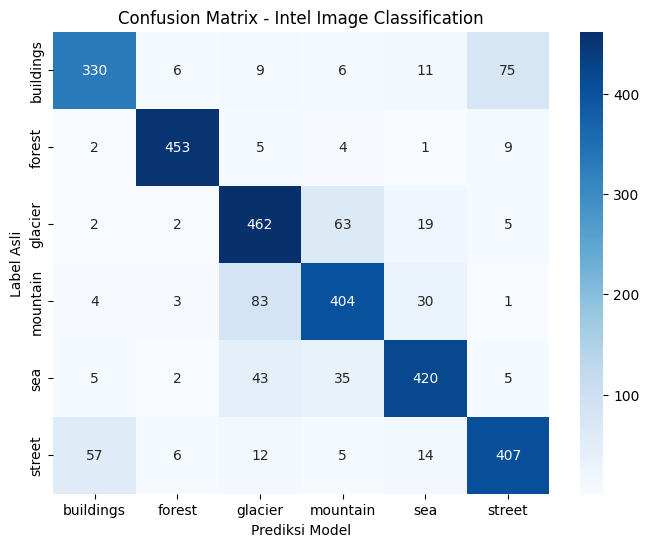

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

y_true = []
y_pred = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("=== CLASSIFICATION REPORT ===")
print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Prediksi Model')
plt.ylabel('Label Asli')
plt.title('Confusion Matrix - Intel Image Classification')
plt.show()

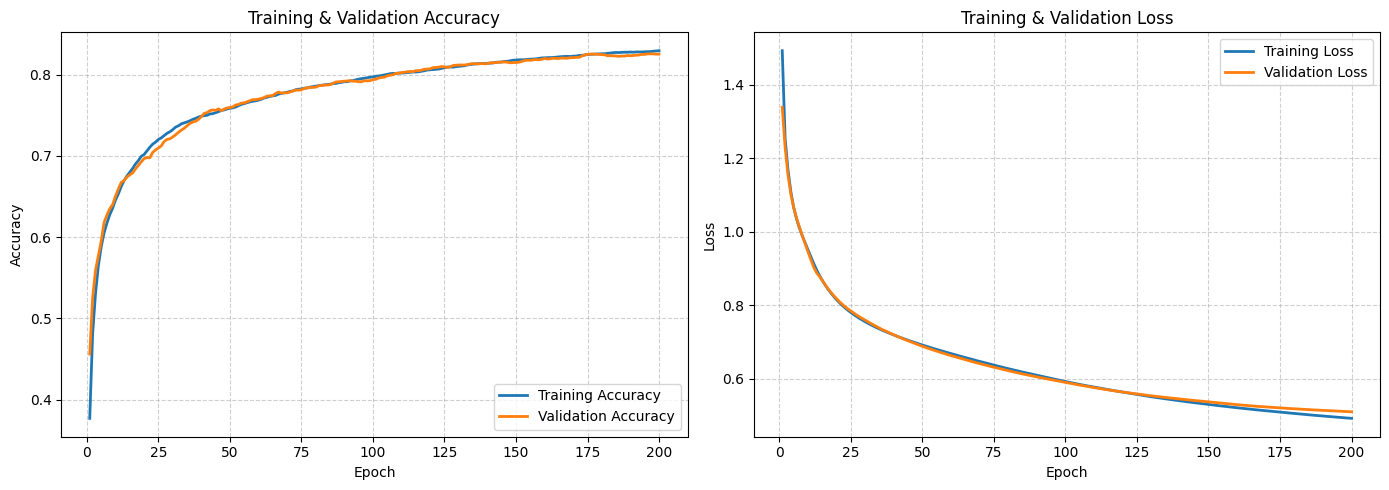

In [28]:
import matplotlib.pyplot as plt

acc      = history.history['accuracy']
val_acc  = history.history['val_accuracy']
loss     = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', linewidth=2)
plt.plot(epochs_range, val_acc, label='Validation Accuracy', linewidth=2)
plt.title('Training & Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', linewidth=2)
plt.plot(epochs_range, val_loss, label='Validation Loss', linewidth=2)
plt.title('Training & Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [ ]:
def save_int8_to_mem(array_float, filename, scale=64.0):
    quantized = np.round(array_float * scale)
    quantized = np.clip(quantized, -128, 127).astype(np.int8)
    flat = quantized.flatten()

    filepath = os.path.join(OUTPUT_DIR, filename)
    with open(filepath, 'w') as f:
        for val in flat:
            hex_val = format(int(val) & 0xFF, '02X')
            f.write(f"{hex_val}\n")
    print(f"Tersimpan: {filepath} | Total baris: {len(flat)}")

w_conv1 = np.transpose(model.get_layer('conv1').get_weights()[0], (3, 2, 0, 1))
save_int8_to_mem(w_conv1, 'conv1_weights.mem', scale=64.0)

w_conv2 = np.transpose(model.get_layer('conv2').get_weights()[0], (3, 2, 0, 1))
save_int8_to_mem(w_conv2, 'conv2_weights.mem', scale=64.0)

w_dense = np.transpose(model.get_layer('dense_out').get_weights()[0], (1, 0))
save_int8_to_mem(w_dense, 'dense_weights.mem', scale=64.0)

for images, labels in test_ds.take(5):
    imgs_np, lbls_np = images.numpy(), labels.numpy()
    break

selected_images = []
for target_class in range(NUM_CLASSES):
    for i in range(len(lbls_np)):
        if lbls_np[i] == target_class:
            pred = np.argmax(model.predict(imgs_np[i:i+1], verbose=0))
            if pred == target_class:
                selected_images.append(imgs_np[i])
                print(f"SW[2:0] = {target_class} ({target_class:03b}) -> Kelas: {target_class} ({class_names[target_class]})")
                break

save_int8_to_mem(np.array(selected_images), 'test_images.mem', scale=127.0)